In [1]:
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection

from tiles.color_policies import (
    DominantColor,
    MeanRGBColor,
    MedianRGBColor,
    MostSaturatedColor,
    OKLabChromaColor,
)
from tiles.input_output import load_images
from tiles.partitioners import QuadtreePartitioner, SlicePartitioner, VoronoiPartitioner
from tiles.recursion import grow_tree
from tiles.statistics import recompute_tile_colors
from tiles.stopping_policies import AnyOf, PerceptualUniformityStop, ThresholdStop

In [2]:
def simple_plotter(tiles, context, img_size=8, ax=None):
    polygons = []
    colors = []

    for tile in tiles:
        polygons.append(tile.region.polygon)
        colors.append(tuple(channel / 255 for channel in tile.color))
        
    vor_coll = PolyCollection(polygons, edgecolors=colors, linewidths=0.5, facecolors=colors, alpha=1)

    width, height = context.size

    if ax is None:
        fig, ax = plt.subplots(figsize=(img_size, img_size * height / width), ncols=1, nrows=1, dpi=75)
    ax.axis("off")
    ax.set_xlim(-1, width + 1)  # image dimensions
    ax.set_ylim(height + 1, -1)  # remember that images have inverted y-axis

    ax.add_collection(vor_coll)

    if ax is None:
        fig.tight_layout(pad=0.2)


In [3]:
# Let's start by loding the context: the image itself and an optional heightmap.
# We also extract the image width and height for later use.
img_path = "/app/src/images/portrait.jpg"
hmap_path = "/app/src/images/hmap.jpg"

context = load_images(image_path=img_path, heightmap_path=hmap_path)
image_width, image_height = context.size

In [4]:
# We will stop the partionionning algorithm based on either a threshold on color standard deviation, the heightmap or perceptual uniformity.
policy = ThresholdStop(standard_deviation=20.0, max_level=6, heightmap_decay=0.05)
policy2 = PerceptualUniformityStop(tolerance=0.1, max_level=6, lightness_weight=1.5)

tiles = grow_tree(
    context=context,
    stop_policy=AnyOf(policy, policy2),
    partitioner=VoronoiPartitioner(),
    color_policy=MeanRGBColor(),
)

# Let's check the number of tiles generated and the seed used for reproducibility.
len(tiles), tiles.seed

(11267, 123089983487478640796589120492911818912)

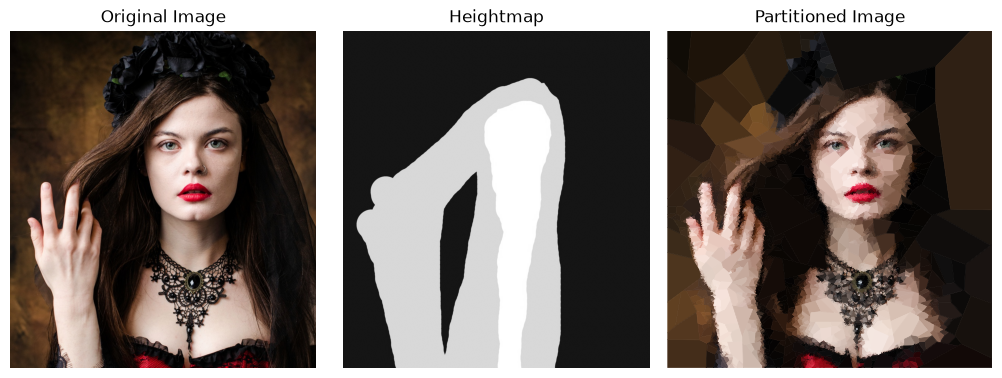

In [5]:
nrows = 1
ncols = 3
fig_width = 10
fig_height = fig_width / ncols * nrows * image_height / image_width

fig, ax = plt.subplots(
    ncols=ncols,
    nrows=nrows,
    figsize=(fig_width, fig_height),
    constrained_layout=True,
)
ax = ax.flatten()

ax[0].imshow(context.image)
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(context.heightmap, cmap="gray")
ax[1].set_title("Heightmap")
ax[1].axis("off")
ax[2].set_title("Partitioned Image")
ax[2].axis("off")
simple_plotter(tiles, context, ax=ax[2])

In [6]:
# Examples of using different partitioners with a threshold stop policy
stop_policy = ThresholdStop(standard_deviation=20.0, max_level=6, heightmap_decay=0.1)
partitioners = [VoronoiPartitioner(), QuadtreePartitioner(level_step=0.8), SlicePartitioner(level_step=0.3)]
partition_examples = []
for i, partitioner in enumerate(partitioners):
    tiles_example = grow_tree(
        context=context,
        stop_policy=AnyOf(stop_policy),
        partitioner=partitioner,
        color_policy=MeanRGBColor(),
    )
    partition_examples.append(tiles_example)


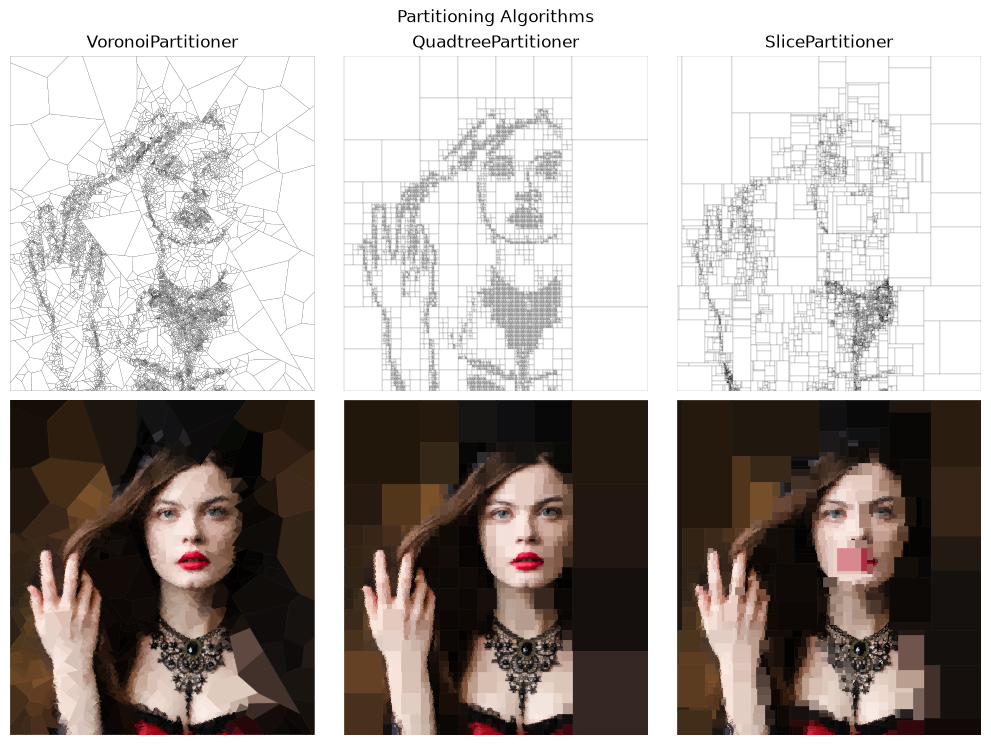

In [7]:
nrows = 2
ncols = 3
fig_width = 10
fig_height = fig_width / ncols * nrows * image_height / image_width

fig, ax = plt.subplots(ncols=ncols, nrows=nrows, figsize=(fig_width, fig_height), constrained_layout=True,)
ax = ax.flatten()

for i, tiles_example in enumerate(partition_examples):
    polygons = []
    colors = []

    for tile in tiles_example:
        polygons.append(tile.region.polygon)
        colors.append(tuple(channel / 255 for channel in tile.color))

    edges_coll = PolyCollection(polygons, edgecolors="k", linewidths=0.1, facecolors="w", alpha=1)
    tiles_coll = PolyCollection(polygons, edgecolors=colors, linewidths=0.5, facecolors=colors, alpha=1)

    ax[i].add_collection(edges_coll)
    ax[i+3].add_collection(tiles_coll)
    ax[i].set_title(type(partitioners[i]).__name__)

width, height = context.size
for a in ax:
    a.axis("off")
    a.set_xlim(-1, width + 1)  # image dimensions
    a.set_ylim(height + 1, -1)  # remember that images have inverted y-axis
    a.set_box_aspect(image_height / image_width)
    a.set_aspect("equal", adjustable="box")

fig.suptitle("Partitioning Algorithms");

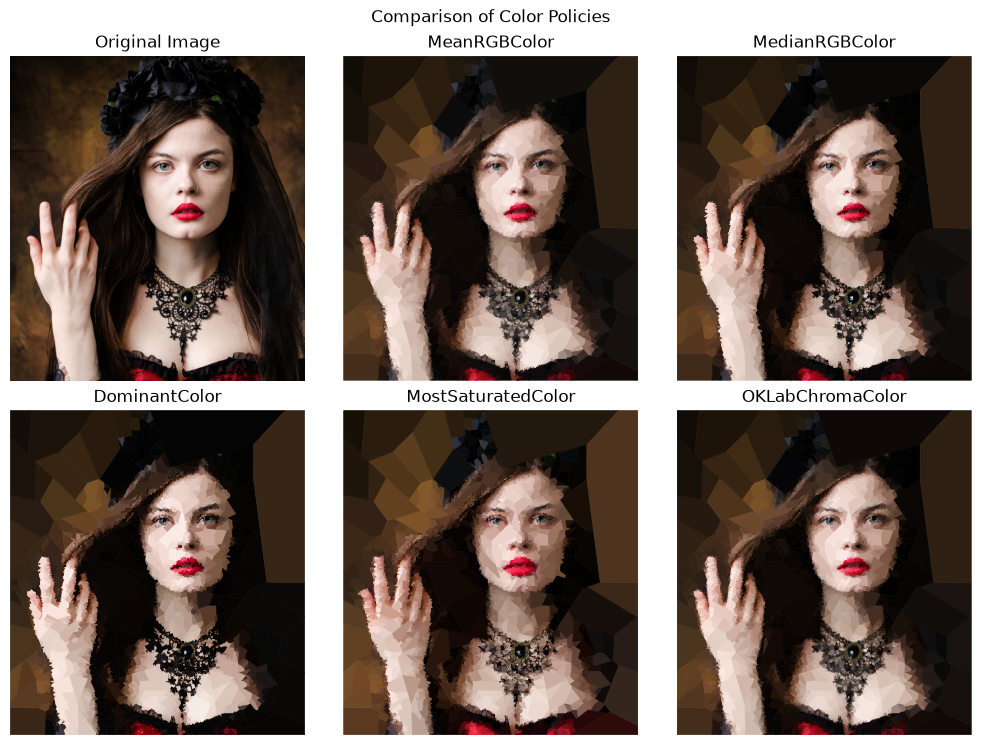

In [8]:
# Examples of different color policies.
color_policies = [MeanRGBColor(), 
                  MedianRGBColor(), 
                  DominantColor(bits=4), 
                  MostSaturatedColor(top_fraction=0.2), 
                  OKLabChromaColor(vividness=1.0),
                  ]

names = ["MeanRGBColor", 
         "MedianRGBColor", 
         "DominantColor", 
         "MostSaturatedColor", 
         "OKLabChromaColor"]

nrows = 2
ncols = 3
fig_width = 10
fig_height = fig_width / ncols * nrows * image_height / image_width

fig, ax = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(fig_width, fig_height),
    constrained_layout=True,
)
ax = ax.ravel()

for i, policy in enumerate(color_policies):
    tiles2 = recompute_tile_colors(tile_set=tiles, context=context, policy=policy)
    simple_plotter(tiles2, context, ax=ax[i+1])
    ax[i+1].set_title(names[i])
    ax[i+1].set_box_aspect(image_height / image_width)
    ax[i+1].set_aspect("equal", adjustable="box")

ax[0].imshow(context.image)
ax[0].set_title("Original Image")
ax[0].axis("off")

fig.suptitle("Comparison of Color Policies");